# Data-Driven Design Basis for Municipal Solid Waste Management in Mueang Rayong
**2107540 Data Science for Environment and Sustainability — Project 1 (Group Project)**
Integrated with **Solid Waste Engineering** (design of a community solid-waste management system)

**Environmental problem.** Rayong is an industrial/coastal province whose municipal solid waste (MSW) rose from 1,425 to 1,598 t/day (2563→2567 B.E.). A service-area study (Mueang Rayong) must decide *how much waste to design for* and *which system to build*: **S1 = sanitary landfill only** vs **S3 = integrated MRF + RDF + compost + residual landfill**.

**Questions this notebook answers**
1. How reliable is the data we are about to design on? (data audit)
2. Where is the waste generated, and how is it concentrated across the 15 local administrative organisations (LAOs)?
3. How has the provincial system evolved (generation, recovery, disposal), and what drove it?
4. What design flows result from the waste composition, and how uncertain are they?
5. How robust is the S3-over-S1 decision when assumptions change?

Workflow = Part 1 collection → 2 cleaning → 3 EDA → 4 analysis & insights → 5 visualisation → 6 basic ML / simulation → environmental interpretation.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170, "axes.titleweight": "bold", "axes.titlesize": 12})

ROOT = Path("..")
RAW, PROC, FIG = ROOT/"data"/"raw", ROOT/"data"/"processed", ROOT/"figures"
PROC.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
RESULTS = {}                                  # key numbers -> results_summary.json (used by README)
PAL = dict(reported="#264653", derived="#aab4be", cluster="#2a9d8f", other="#e9c46a",
           S1="#c0392b", S3="#2a9d8f", accent="#e76f51", blue="#3b6ea5")

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG/f"{name}.png", bbox_inches="tight"); plt.show()

---
## Part 1 — Data Collection
Three compiled inputs were provided for the study (all in `data/raw/`). The primary sources they cite are listed in sheet 4 of the workbook.

| File | Content |
|---|---|
| `rayong_msw_raw_data.xlsx` | (1) monthly 2568 B.E. waste of 15 LAOs in Mueang Rayong + population; (2) province time series 2563–2568; (3) disposal projects/contracts + design alternatives S1/S3; (4) source list |
| `rayong_msw_summary.pdf` | Narrative summary, LAO table (Table 1) and design composition table (Table 2) |
| `composition_from_pdf.csv`, `design_alternatives_from_xlsx.csv` | **Hand-transcribed** machine-readable versions of PDF Table 2 and the S1/S3 text in sheet 3 (values verified in Part 2) |

*Primary sources cited by the workbook:* PCD Region 13 *Eastern Environmental Situation Report 2567*; Rayong PAO integrated disposal centre (Nam Khok); PCD Region 13 monitoring report for Map Ta Phut transfer station; Rayong provincial waste committee minutes; Taphong municipality reference-price document; Kasetsart Univ. × Rayong PAO composition study; TMD 30-year climate statistics.

In [2]:
XLSX = RAW / "rayong_msw_raw_data.xlsx"
xl = pd.ExcelFile(XLSX)
for i, s in enumerate(xl.sheet_names):
    print(f"[{i}] {s}  -> {xl.parse(s).shape}")

[0] ขยะมูลฝอยราย อปท. เมืองระยอง  -> (17, 17)
[1] ขยะมูลฝอย จ.ระยอง 63-68  -> (8, 11)
[2] โครงการกำจัดขยะ จ.ระยอง  -> (9, 8)
[3] ที่มา  -> (7, 2)


---
## Part 2 — Data Cleaning and Transformation
Steps: (a) translate/standardise column names, (b) drop spreadsheet "total" rows and **re-compute every formula independently** (we do not trust cached sheet formulas), (c) reshape monthly data to long format, (d) attach metadata (zone, urban-cluster membership, tonnage basis), (e) **validate against the PDF** and run internal-consistency checks, (f) save tidy tables to `data/processed/`.

In [3]:
months = list(range(1, 13)); mcols = [f"m{m:02d}" for m in months]
days_in_month = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])

lao_raw = pd.read_excel(XLSX, sheet_name=0).iloc[:, :14]
lao_raw.columns = ["lao_th", "population"] + mcols
lao = lao_raw[~lao_raw["lao_th"].astype(str).str.startswith("รวม")].reset_index(drop=True).copy()
assert len(lao) == 15

meta = pd.DataFrame({
    "lao_en": ["Rayong City Mun.", "Thap Ma Mun.", "Choeng Noen Mun.", "Noen Phra Mun.", "Taphong Mun.", "Nam Khok Mun.",
               "Map Ta Phut City Mun.", "Ban Phe Mun.", "Phe SAO (+Ko Samet)", "Klaeng Kachet Mun.",
               "Kachet SAO", "Ban Laeng SAO", "Klaeng SAO", "Na Ta Khwan SAO", "Samnak Thong SAO"],
    "in_urban_cluster": [True]*6 + [False]*9,
    "zone": ["Urban core"]*6 + ["Industrial", "Coastal / tourism", "Coastal / tourism", "Peripheral"] + ["Agri / semi-urban"]*5,
    # How the tonnage in PDF Table 1 was obtained: measured/reported/contract figure vs. population x 1.30 kg/cap/day
    "tonnage_basis": ["reported", "reported", "derived", "derived", "reported", "derived",
                      "reported", "reported", "reported", "derived"] + ["derived"]*5,
})
lao = pd.concat([meta, lao], axis=1)
lao["population"] = lao["population"].astype(float)
lao["annual_t"] = lao[mcols].sum(axis=1)
lao["tpd"] = lao["annual_t"] / 365
lao["kg_cap_day"] = lao["tpd"] * 1000 / lao["population"]
lao["share_district_pct"] = 100 * lao["tpd"] / lao["tpd"].sum()

long = lao.melt(id_vars=["lao_en", "in_urban_cluster", "zone"], value_vars=mcols, var_name="month", value_name="tonnes")
long["month"] = long["month"].str[1:].astype(int)
long["days"] = days_in_month[long["month"] - 1]
long["tpd_in_month"] = long["tonnes"] / long["days"]

lao.to_csv(PROC/"lao_annual.csv", index=False)
long.to_csv(PROC/"lao_monthly_long.csv", index=False)
display(lao[["lao_en", "zone", "tonnage_basis", "population", "annual_t", "tpd", "kg_cap_day"]].round(3))

,lao_en,zone,tonnage_basis,population,annual_t,tpd,kg_cap_day
0,Rayong City Mun.,Urban core,reported,88462.0,41975.0,115.000,1.3
1,Thap Ma Mun.,Urban core,reported,34615.0,16425.0,45.000,1.3
2,Choeng Noen Mun.,Urban core,derived,34615.0,16425.0,45.000,1.3
3,Noen Phra Mun.,Urban core,derived,23077.0,10950.0,30.000,1.3
4,Taphong Mun.,Urban core,reported,8363.0,3968.2,10.872,1.3
5,Nam Khok Mun.,Urban core,derived,6252.0,2966.8,8.128,1.3
6,Map Ta Phut City Mun.,Industrial,reported,115385.0,54750.0,150.000,1.3
7,Ban Phe Mun.,Coastal / tourism,reported,16923.0,8030.0,22.000,1.3
8,Phe SAO (+Ko Samet),Coastal / tourism,reported,13846.0,6570.0,18.000,1.3
9,Klaeng Kachet Mun.,Peripheral,derived,7692.0,3650.0,10.000,1.3


In [4]:
# ---- Province time series (sheet 2) and design-area rows
prov_raw = pd.read_excel(XLSX, sheet_name=1).iloc[:, :9]
prov_raw.columns = ["label_th", "pop_registered", "pop_floating", "pop_total_sheet", "gen_tpd",
                    "recovered_tpd", "disposed_ok_tpd", "disposed_bad_tpd", "backlog_t"]
prov = prov_raw.iloc[:6].copy().reset_index(drop=True)
prov["year_be"] = [2563, 2564, 2565, 2566, 2567, 2568]
prov["status"] = ["series", "series", "series", "series", "observed (PCD-13)", "provincial plan"]
prov["pop_total"] = prov["pop_registered"] + prov["pop_floating"]
prov["kg_cap_total"] = prov["gen_tpd"] * 1000 / prov["pop_total"]
prov["kg_cap_registered_only"] = prov["gen_tpd"] * 1000 / prov["pop_registered"]
prov["recovery_rate_pct"] = 100 * prov["recovered_tpd"] / prov["gen_tpd"]
prov["floating_share_pct"] = 100 * prov["pop_floating"] / prov["pop_total"]
prov["implied_floating_at_1p30"] = prov["gen_tpd"] * 1000 / 1.30 - prov["pop_registered"]
prov = prov.drop(columns=["label_th", "pop_total_sheet"])
design_area = prov_raw.iloc[6:].copy().reset_index(drop=True)
prov.to_csv(PROC/"province_yearly.csv", index=False)
display(prov.round(3))

,pop_registered,pop_floating,gen_tpd,recovered_tpd,disposed_ok_tpd,disposed_bad_tpd,backlog_t,year_be,status,pop_total,kg_cap_total,kg_cap_registered_only,recovery_rate_pct,floating_share_pct,implied_floating_at_1p30
0,741524,395000,1425.11,441.59,963.52,20,12500,2563,series,1136524,1.254,1.922,30.986,34.755,354714.462
1,751343,405000,1468.50,469.90,980.60,18,9800,2564,series,1156343,1.270,1.955,31.999,35.024,378272.385
2,759285,418000,1512.40,499.10,998.30,15,6500,2565,series,1177285,1.285,1.992,33.001,35.505,404099.615
3,766574,432000,1558.20,537.50,1008.70,12,3200,2566,series,1198574,1.300,2.033,34.495,36.043,432041.385
4,771126,458190,1598.11,604.45,983.66,10,0,2567,observed (PCD-13),1229316,1.300,2.072,37.823,37.272,458189.385
5,776500,465000,1613.95,619.95,994.00,0,0,2568,provincial plan,1241500,1.300,2.078,38.412,37.455,465000.000


In [5]:
# ---- Composition table (PDF Table 2), design alternatives, facilities
comp = pd.read_csv(RAW/"composition_from_pdf.csv")
alt = pd.read_csv(RAW/"design_alternatives_from_xlsx.csv")
fac = pd.read_excel(XLSX, sheet_name=2).iloc[:, :8]
fac.columns = ["site", "project", "organisation", "detail", "budget_baht", "term", "full_name", "note"]

# annual tonnage behind each budget (taken from the text of the same rows) -> baht per tonne
tpy = {"ศูนย์กำจัดขยะมูลฝอยรวมแบบครบวงจร จังหวัดระยอง": 983.66*365,
       "โครงการเก็บขนและส่งกำจัดขยะมูลฝอยในเขตเทศบาลนครระยอง": 115*365,
       "โครงการบริหารจัดการสถานีขนถ่ายขยะมูลฝอยและจ้างเหมาขนส่งไปกำจัด ณ ศูนย์กำจัดขยะรวม อบจ.ระยอง": 150*365,
       "โครงการเก็บขนและกำจัดขยะมูลฝอยเทศบาลตำบลทับมา": 45*365,
       "โครงการจ้างเหมาเก็บขนขยะมูลฝอยในเขตเทศบาลตำบลตะพง": 3968.19,
       "โครงการจ้างเหมาเก็บขนและกำจัดขยะมูลฝอยเทศบาลตำบลบ้านเพ": 8030.0}
fac_cost = fac[fac["project"].isin(tpy)].copy()
fac_cost["tonnes_per_year"] = fac_cost["project"].map(tpy)
fac_cost["baht_per_tonne"] = fac_cost["budget_baht"] / fac_cost["tonnes_per_year"]
fac_cost["site_short"] = ["Nam Khok centre (PAO)", "Rayong City", "Map Ta Phut", "Thap Ma", "Taphong", "Ban Phe"]
fac_cost[["site_short", "budget_baht", "tonnes_per_year", "baht_per_tonne"]].to_csv(PROC/"facility_budget_per_tonne.csv", index=False)
display(fac_cost[["site_short", "budget_baht", "tonnes_per_year", "baht_per_tonne"]].round(1))

,site_short,budget_baht,tonnes_per_year,baht_per_tonne
0,Nam Khok centre (PAO),178840000,359035.9,498.1
2,Rayong City,27375000,54750.0,500.0
3,Map Ta Phut,20987500,41975.0,500.0
4,Thap Ma,8212500,16425.0,500.0
5,Taphong,4560000,3968.2,1149.1
6,Ban Phe,6424000,8030.0,800.0


In [6]:
# ---- Validation & consistency checks (every row = one test; nothing is silently assumed)
checks = []
def chk(name, expected, observed, tol):
    checks.append(dict(check=name, expected=expected, observed=round(float(observed), 3),
                       abs_diff=round(abs(float(observed) - expected), 3), passed=bool(abs(float(observed) - expected) <= tol)))

cl, di = lao[lao.in_urban_cluster], lao
chk("Urban-cluster generation = 254.00 t/d (PDF Table 1)", 254.00, cl.tpd.sum(), 0.01)
chk("District generation = 490.00 t/d (PDF Table 1)", 490.00, di.tpd.sum(), 0.01)
chk("Urban-cluster annual = 92,710 t/y (PDF)", 92710.0, cl.annual_t.sum(), 1)
chk("District annual = 178,850 t/y (PDF)", 178850.0, di.annual_t.sum(), 1)
chk("Taphong annual = 3,968.2 t/y (PDF / reference-price doc)", 3968.2, lao.loc[lao.lao_en == "Taphong Mun.", "annual_t"].iloc[0], 0.1)
chk("Composition shares sum to 100 %", 100.0, comp.share_pct.sum(), 1e-9)
chk("Cluster MRF feed = 254 x 365/300 = 309.03 t/working-day", 309.03, 254*365/300, 0.01)
chk("District MRF feed = 490 x 365/300 = 596.17 t/working-day", 596.17, 490*365/300, 0.01)
chk("Composition x 254 t/d reproduces PDF cluster column", comp.cluster_tpd_365.sum(), (comp.share_pct/100*254).sum(), 0.05)
chk("Province: recovered + proper + improper disposal = generation (max error, t/d)", 0.0,
    (prov.recovered_tpd + prov.disposed_ok_tpd + prov.disposed_bad_tpd - prov.gen_tpd).abs().max(), 0.05)
chk("Centre throughput 983.66 t/d = province 2567 properly-disposed", 983.66, prov.loc[prov.year_be == 2567, "disposed_ok_tpd"].iloc[0], 0.001)
chk("Cluster population = 145,384 registered + 50,000 floating", 195384.0, cl.population.sum(), 1)
chk("Province per-capita rate 2567 = 1.30 kg/cap/d (provincial plan rate)", 1.30, prov.loc[prov.year_be == 2567, "kg_cap_total"].iloc[0], 0.005)
audit = pd.DataFrame(checks); audit.to_csv(PROC/"audit_checks.csv", index=False)
display(audit)
RESULTS["checks_passed"] = int(audit.passed.sum()); RESULTS["checks_total"] = len(audit)
print(f"{audit.passed.sum()} / {len(audit)} validation checks passed")

,check,expected,observed,abs_diff,passed
0,Urban-cluster generation = 254.00 t/d (PDF Tab...,254.00,254.000,0.000,True
1,District generation = 490.00 t/d (PDF Table 1),490.00,490.000,0.000,True
2,"Urban-cluster annual = 92,710 t/y (PDF)",92710.00,92710.000,0.000,True
3,"District annual = 178,850 t/y (PDF)",178850.00,178850.000,0.000,True
4,"Taphong annual = 3,968.2 t/y (PDF / reference-...",3968.20,3968.200,0.000,True
5,Composition shares sum to 100 %,100.00,100.000,0.000,True
6,Cluster MRF feed = 254 x 365/300 = 309.03 t/wo...,309.03,309.033,0.003,True
7,District MRF feed = 490 x 365/300 = 596.17 t/w...,596.17,596.167,0.003,True
8,Composition x 254 t/d reproduces PDF cluster c...,254.00,254.000,0.000,True
9,Province: recovered + proper + improper dispos...,0.00,0.000,0.000,True


13 / 13 validation checks passed


**What the cleaning/validation tells us.** All arithmetic ties out to the PDF, so the numbers are *internally consistent*. Consistency is not the same as independence, though — Part 3 shows how much of the table is measured and how much is modelled.

---
## Part 3 — Exploratory Data Analysis (EDA)
### 3.1 Is the data independent evidence, or a model?
Two things to test: (i) does per-capita generation vary between LAOs? (ii) does monthly generation show real seasonality once we correct for the number of days in the month?

Per-capita generation across 15 LAOs: min 1.2999, max 1.3001 kg/cap/day
Max coefficient of variation of the *daily* rate across the 12 months: 2.45e-05


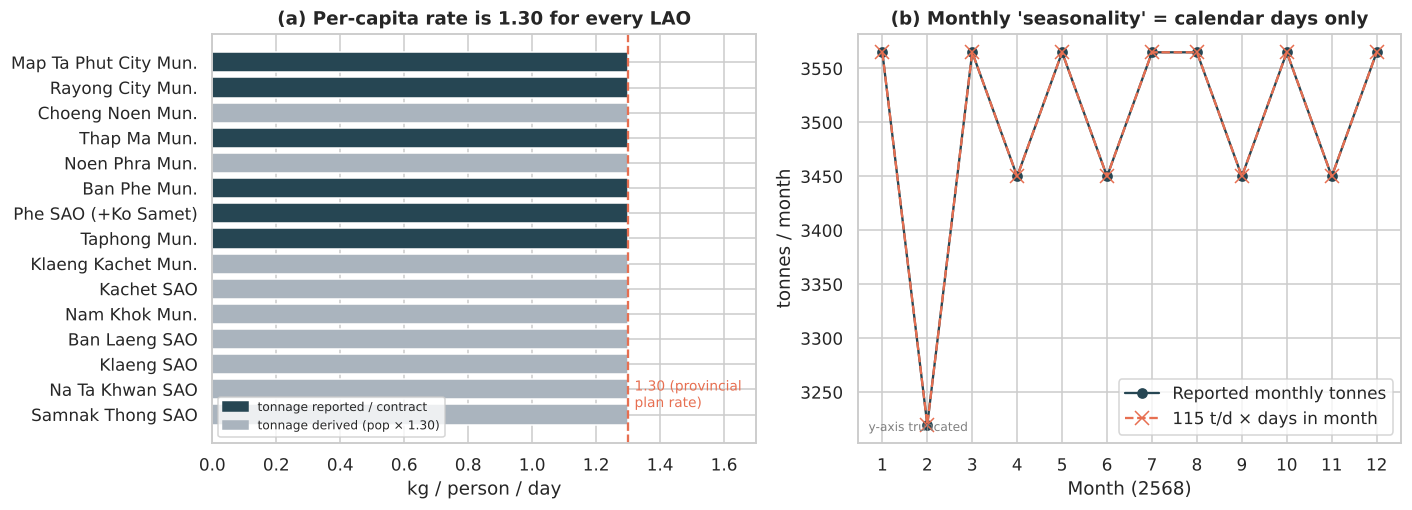

In [7]:
cv_daily = long.groupby("lao_en")["tpd_in_month"].agg(lambda s: s.std() / s.mean())
RESULTS["kg_cap_min"], RESULTS["kg_cap_max"] = float(lao.kg_cap_day.min()), float(lao.kg_cap_day.max())
RESULTS["max_cv_daily_rate"] = float(cv_daily.max())
print(f"Per-capita generation across 15 LAOs: min {lao.kg_cap_day.min():.4f}, max {lao.kg_cap_day.max():.4f} kg/cap/day")
print(f"Max coefficient of variation of the *daily* rate across the 12 months: {cv_daily.max():.2e}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
o = lao.sort_values("tpd")
ax[0].barh(o.lao_en, o.kg_cap_day, color=[PAL["reported"] if b == "reported" else PAL["derived"] for b in o.tonnage_basis])
ax[0].axvline(1.30, ls="--", c=PAL["accent"]); ax[0].set_xlim(0, 1.7)
ax[0].set_xlabel("kg / person / day"); ax[0].set_title("(a) Per-capita rate is 1.30 for every LAO")
ax[0].text(1.32, 0.3, "1.30 (provincial\nplan rate)", color=PAL["accent"], fontsize=9)
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PAL["reported"]), plt.Rectangle((0, 0), 1, 1, color=PAL["derived"])],
             labels=["tonnage reported / contract", "tonnage derived (pop × 1.30)"], loc="lower left", fontsize=8)
rc = long[long.lao_en == "Rayong City Mun."].sort_values("month")
ax[1].plot(rc.month, rc.tonnes, "o-", color=PAL["reported"], label="Reported monthly tonnes")
ax[1].plot(rc.month, 115 * rc.days, "x--", color=PAL["accent"], ms=9, label="115 t/d × days in month")
ax[1].set_xticks(range(1, 13)); ax[1].set_xlabel("Month (2568)"); ax[1].set_ylabel("tonnes / month")
ax[1].set_title("(b) Monthly 'seasonality' = calendar days only"); ax[1].legend(loc="lower right")
ax[1].text(0.02, 0.03, "y-axis truncated", transform=ax[1].transAxes, fontsize=8, color="grey")
savefig("fig01_data_audit_percapita_and_monthly")

**Finding 1 (data audit).** Per-capita generation equals 1.30 kg/cap/day for *all 15* LAOs and the monthly series is exactly *(daily rate × days in month)* — zero real seasonality. Consequently:
* the population column for many LAOs is back-calculated (tonnes ÷ 1.30) or tonnes are population × 1.30 — they are not independent variables, so **regressing waste on population would be circular**;
* seasonal effects (tourism at Ban Phe/Ko Samet, rainy-season moisture) **cannot be learned from this dataset** and must be treated as design uncertainty.

We therefore classify every LAO's tonnage as *reported* (measured/contract/meeting-report figure) or *derived* (population × 1.30).

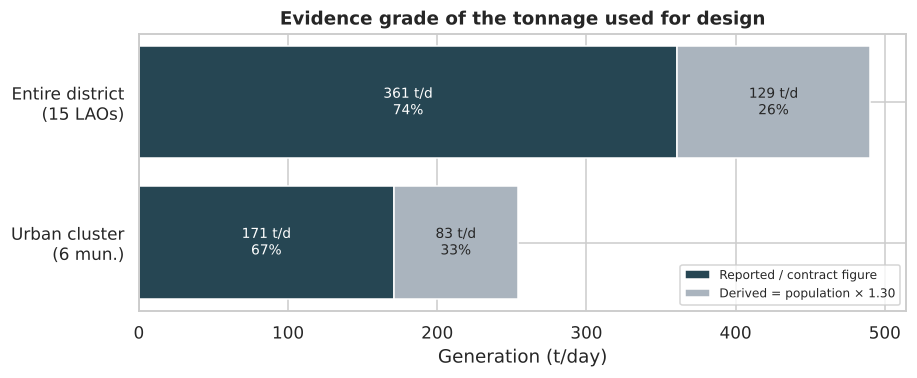

In [8]:
prov_basis = (lao.groupby(["in_urban_cluster", "tonnage_basis"]).tpd.sum().unstack(fill_value=0))
prov_basis.index = ["Rest of district (9 LAOs)", "Urban cluster (6 mun.)"]
d_tot = lao.groupby("tonnage_basis").tpd.sum()
RESULTS["district_reported_share_pct"] = float(100 * d_tot["reported"] / d_tot.sum())
RESULTS["district_derived_share_pct"] = float(100 * d_tot["derived"] / d_tot.sum())
c_tot = lao[lao.in_urban_cluster].groupby("tonnage_basis").tpd.sum()
RESULTS["cluster_reported_share_pct"] = float(100 * c_tot["reported"] / c_tot.sum())
RESULTS["cluster_derived_share_pct"] = float(100 * c_tot["derived"] / c_tot.sum())

fig, ax = plt.subplots(figsize=(8.5, 3.6))
y = [0, 1]; labs = ["Urban cluster\n(6 mun.)", "Entire district\n(15 LAOs)"]
rep = [c_tot["reported"], d_tot["reported"]]; der = [c_tot["derived"], d_tot["derived"]]
ax.barh(y, rep, color=PAL["reported"], label="Reported / contract figure")
ax.barh(y, der, left=rep, color=PAL["derived"], label="Derived = population × 1.30")
for yi, r, d in zip(y, rep, der):
    ax.text(r/2, yi, f"{r:.0f} t/d\n{100*r/(r+d):.0f}%", ha="center", va="center", color="white", fontsize=9)
    ax.text(r + d/2, yi, f"{d:.0f} t/d\n{100*d/(r+d):.0f}%", ha="center", va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(labs); ax.set_xlabel("Generation (t/day)"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Evidence grade of the tonnage used for design")
savefig("fig02_evidence_grade")

### 3.2 Where is the waste? Spatial concentration across LAOs

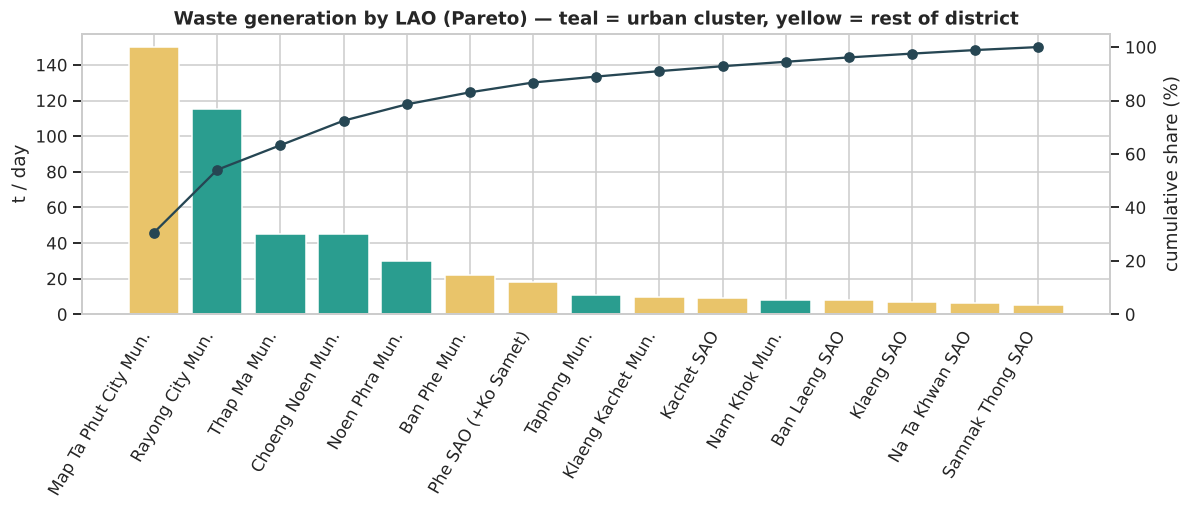

Top-2 LAOs = 54.1% of district waste; top-5 = 78.6%; HHI = 1751


In [9]:
o = lao.sort_values("tpd", ascending=False).reset_index(drop=True)
o["cum_share"] = o.tpd.cumsum() / o.tpd.sum() * 100
hhi = float(((o.tpd / o.tpd.sum())**2).sum() * 10000)
RESULTS.update(top2_share_pct=float(o.share_district_pct.iloc[:2].sum()), top5_share_pct=float(o.share_district_pct.iloc[:5].sum()),
               hhi=hhi, mtp_share_pct=float(o.loc[o.lao_en == "Map Ta Phut City Mun.", "share_district_pct"].iloc[0]),
               cluster_share_of_district_pct=float(100 * lao[lao.in_urban_cluster].tpd.sum() / lao.tpd.sum()))
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(o.lao_en, o.tpd, color=[PAL["cluster"] if c else PAL["other"] for c in o.in_urban_cluster])
ax.set_ylabel("t / day"); ax.tick_params(axis="x", rotation=60)
for lbl in ax.get_xticklabels(): lbl.set_ha("right")
ax2 = ax.twinx(); ax2.plot(o.lao_en, o.cum_share, "o-", color=PAL["reported"]); ax2.set_ylim(0, 105); ax2.set_ylabel("cumulative share (%)"); ax2.grid(False)
ax.set_title("Waste generation by LAO (Pareto) — teal = urban cluster, yellow = rest of district")
savefig("fig03_lao_pareto")
print(f"Top-2 LAOs = {RESULTS['top2_share_pct']:.1f}% of district waste; top-5 = {RESULTS['top5_share_pct']:.1f}%; HHI = {hhi:.0f}")

### 3.3 Province time series 2563–2568 B.E.

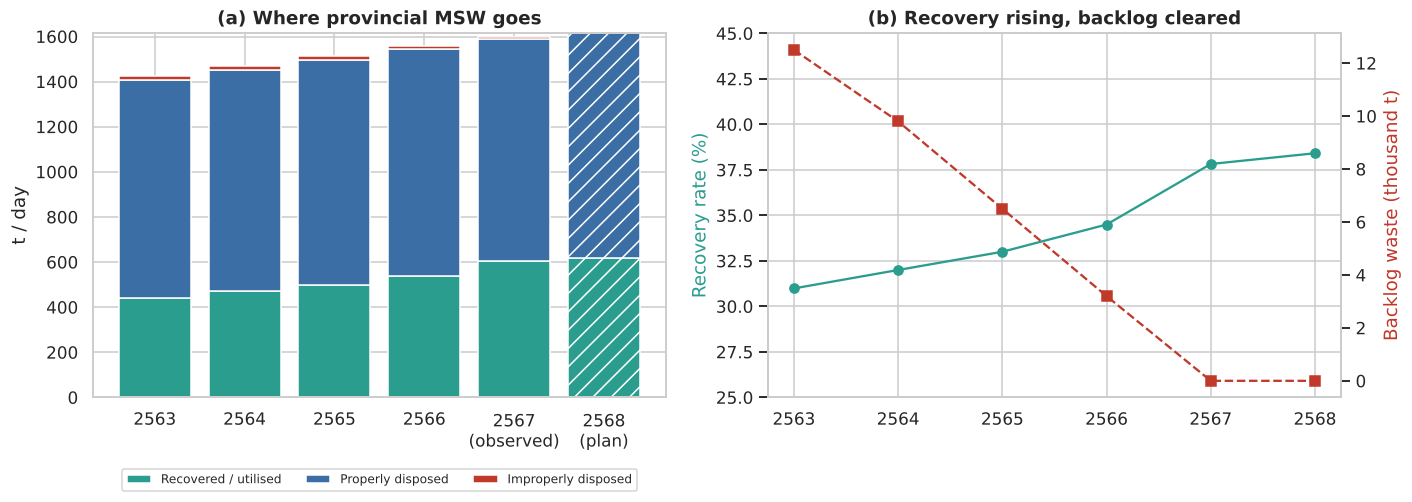

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
x = prov.year_be.astype(str)
ax[0].bar(x, prov.recovered_tpd, color=PAL["S3"], label="Recovered / utilised")
ax[0].bar(x, prov.disposed_ok_tpd, bottom=prov.recovered_tpd, color=PAL["blue"], label="Properly disposed")
ax[0].bar(x, prov.disposed_bad_tpd, bottom=prov.recovered_tpd + prov.disposed_ok_tpd, color=PAL["S1"], label="Improperly disposed")
for i in (5, 11, 17): ax[0].patches[i].set_hatch("//")
ax[0].set_xticks(range(6)); ax[0].set_xticklabels(["2563", "2564", "2565", "2566", "2567\n(observed)", "2568\n(plan)"])
ax[0].set_ylabel("t / day"); ax[0].set_title("(a) Where provincial MSW goes"); ax[0].legend(loc="upper center", bbox_to_anchor=(.5, -.18), ncol=3, fontsize=8)
ax[1].plot(x, prov.recovery_rate_pct, "o-", color=PAL["S3"], label="Recovery rate (%)")
ax[1].set_ylabel("Recovery rate (%)", color=PAL["S3"]); ax[1].set_ylim(25, 45)
a2 = ax[1].twinx(); a2.plot(x, prov.backlog_t/1000, "s--", color=PAL["S1"]); a2.set_ylabel("Backlog waste (thousand t)", color=PAL["S1"]); a2.grid(False)
ax[1].set_title("(b) Recovery rising, backlog cleared")
savefig("fig04_province_trend")

---
## Part 4 — Data Analysis and Insights Extraction
### 4.1 What drove provincial growth 2563 → 2567? (growth attribution)

Generation             173.00
Recovered              162.86
Properly disposed       20.14
Improperly disposed    -10.00

CAGR 2563→2567 = 2.91 %/yr;  94% of the added waste went to recovery


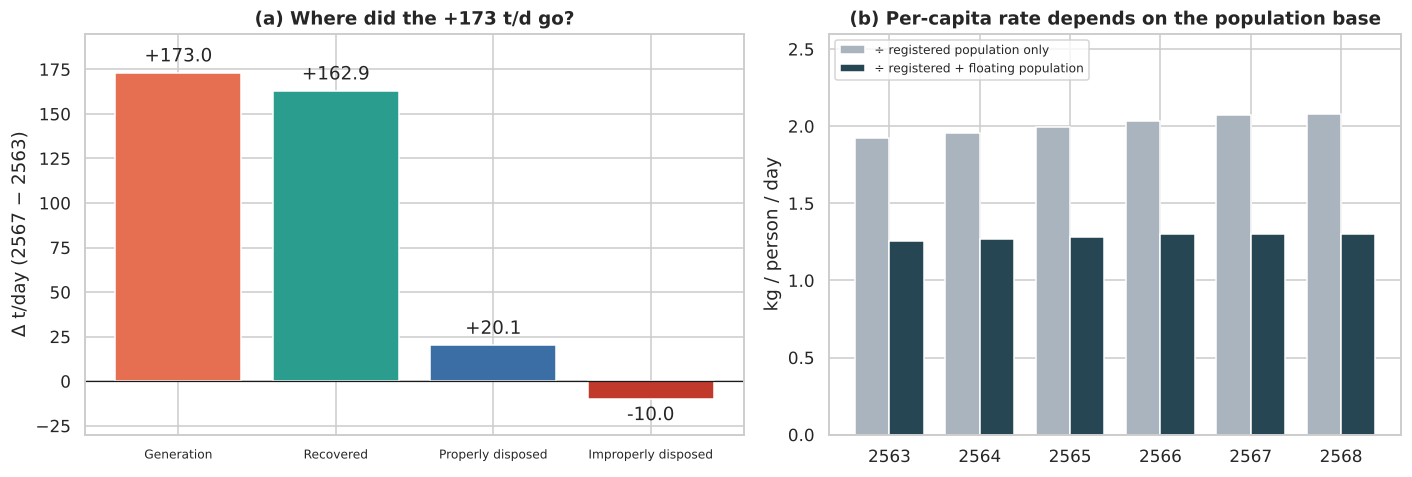

In [11]:
a, b = prov[prov.year_be == 2563].iloc[0], prov[prov.year_be == 2567].iloc[0]
delta = pd.Series({"Generation": b.gen_tpd - a.gen_tpd, "Recovered": b.recovered_tpd - a.recovered_tpd,
                   "Properly disposed": b.disposed_ok_tpd - a.disposed_ok_tpd, "Improperly disposed": b.disposed_bad_tpd - a.disposed_bad_tpd})
cagr = (b.gen_tpd / a.gen_tpd) ** (1/4) - 1
RESULTS.update(gen_2563=float(a.gen_tpd), gen_2567=float(b.gen_tpd), cagr_pct=float(100*cagr), delta_gen=float(delta["Generation"]),
               delta_recovered=float(delta["Recovered"]), delta_ok=float(delta["Properly disposed"]), delta_bad=float(delta["Improperly disposed"]),
               share_growth_recovered_pct=float(100*delta["Recovered"]/delta["Generation"]),
               recovery_2563=float(a.recovery_rate_pct), recovery_2567=float(b.recovery_rate_pct),
               kg_cap_registered_2567=float(b.kg_cap_registered_only), kg_cap_total_2567=float(b.kg_cap_total),
               floating_share_2567=float(b.floating_share_pct), floating_share_2563=float(a.floating_share_pct))
print(delta.round(2).to_string()); print(f"\nCAGR 2563→2567 = {100*cagr:.2f} %/yr;  {RESULTS['share_growth_recovered_pct']:.0f}% of the added waste went to recovery")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.15, 1]})
cols = [PAL["accent"], PAL["S3"], PAL["blue"], PAL["S1"]]
ax[0].bar(delta.index, delta.values, color=cols)
for i, v in enumerate(delta.values): ax[0].text(i, v + 4 if v >= 0 else v - 4, f"{v:+.1f}", ha="center", va="bottom" if v >= 0 else "top")
ax[0].set_ylim(-30, 195)
ax[0].axhline(0, c="k", lw=.8); ax[0].set_ylabel("Δ t/day (2567 − 2563)"); ax[0].set_title("(a) Where did the +173 t/d go?")
ax[0].tick_params(axis="x", labelsize=8)
w = .38; xx = np.arange(len(prov))
ax[1].bar(xx - w/2, prov.kg_cap_registered_only, w, color=PAL["derived"], label="÷ registered population only")
ax[1].bar(xx + w/2, prov.kg_cap_total, w, color=PAL["reported"], label="÷ registered + floating population")
ax[1].set_xticks(xx); ax[1].set_xticklabels(prov.year_be); ax[1].set_ylabel("kg / person / day"); ax[1].set_ylim(0, 2.6); ax[1].legend(fontsize=8, loc="upper left")
ax[1].set_title("(b) Per-capita rate depends on the population base")
savefig("fig05_growth_attribution_and_percapita_base")

**Insight 2.** Almost all growth since 2563 was absorbed by *recovery* (not by more disposal): properly-disposed tonnage stayed ~960–1,010 t/d — i.e. the central facility ran at a plateau while recovery carried the growth.
**Insight 3.** The "per-capita" rate is a function of the population base: dividing by registered residents gives ≈2.1 kg/cap/day, dividing by residents + floating population gives 1.30. A design that uses registered population only would over-state per-capita generation, and one that uses the floating population without verifying it would hide the real uncertainty. *Floating population is not independently measured here* (see check below).

In [12]:
chk_float = prov[["year_be", "status", "pop_floating", "implied_floating_at_1p30"]].copy()
chk_float["difference_persons"] = (chk_float.pop_floating - chk_float.implied_floating_at_1p30).round(0)
display(chk_float.round(0))
RESULTS["floating_backcalc_max_diff_2567_2568"] = float(chk_float.loc[chk_float.year_be >= 2567, "difference_persons"].abs().max())

,year_be,status,pop_floating,implied_floating_at_1p30,difference_persons
0,2563,series,395000,354714.0,40286.0
1,2564,series,405000,378272.0,26728.0
2,2565,series,418000,404100.0,13900.0
3,2566,series,432000,432041.0,-41.0
4,2567,observed (PCD-13),458190,458189.0,1.0
5,2568,provincial plan,465000,465000.0,0.0


### 4.2 Design-basis mass flows by waste fraction

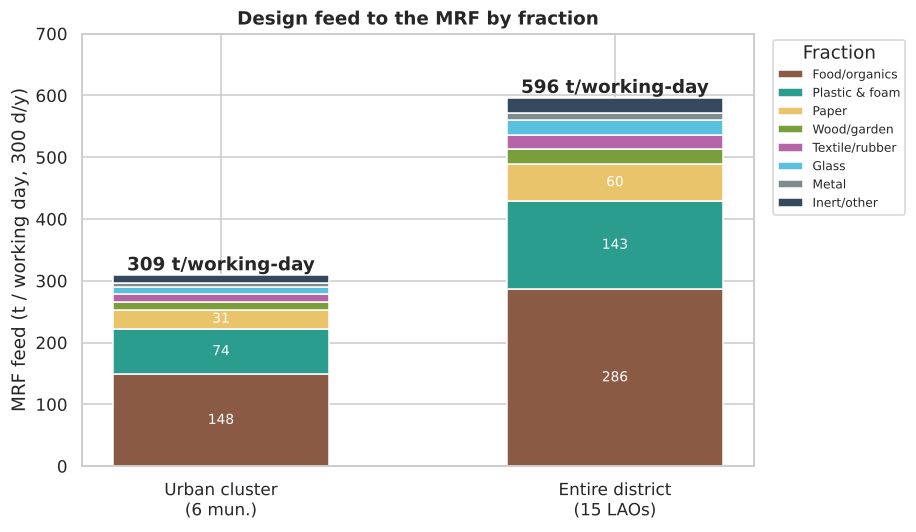

365→300 working-day factor = 1.217: every line must be sized 21.7% above the calendar-day average


In [13]:
short = ["Food/organics", "Plastic & foam", "Paper", "Wood/garden", "Textile/rubber", "Glass", "Metal", "Inert/other"]
palette = ["#8a5a44", "#2a9d8f", "#e9c46a", "#7a9e3b", "#b565a7", "#5bc0de", "#7f8c8d", "#34495e"]
fig, ax = plt.subplots(figsize=(8.5, 5))
for j, (sc, lab) in enumerate([("cluster_mrf_tpd_300", "Urban cluster\n(6 mun.)"), ("district_mrf_tpd_300", "Entire district\n(15 LAOs)")]):
    bottom = 0
    for k in range(len(comp)):
        v = comp[sc].iloc[k]; ax.bar(j, v, bottom=bottom, color=palette[k], label=short[k] if j == 0 else None, width=.55)
        if v > 25: ax.text(j, bottom + v/2, f"{v:.0f}", ha="center", va="center", color="white", fontsize=9)
        bottom += v
    ax.text(j, bottom + 8, f"{bottom:.0f} t/working-day", ha="center", fontweight="bold")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Urban cluster\n(6 mun.)", "Entire district\n(15 LAOs)"]); ax.set_ylabel("MRF feed (t / working day, 300 d/y)")
ax.set_ylim(0, 700); ax.legend(title="Fraction", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax.set_title("Design feed to the MRF by fraction")
savefig("fig06_design_flows_by_fraction")
RESULTS["mrf_cluster"] = 309.03; RESULTS["mrf_district"] = 596.17
RESULTS["organics_cluster_mrf"] = float(comp.cluster_mrf_tpd_300.iloc[0]); RESULTS["plastic_cluster_mrf"] = float(comp.cluster_mrf_tpd_300.iloc[1])
RESULTS["working_day_factor"] = 365/300
print(f"365→300 working-day factor = {365/300:.3f}: every line must be sized {100*(365/300-1):.1f}% above the calendar-day average")

### 4.3 S3 mass balance — does the design account for all the mass?

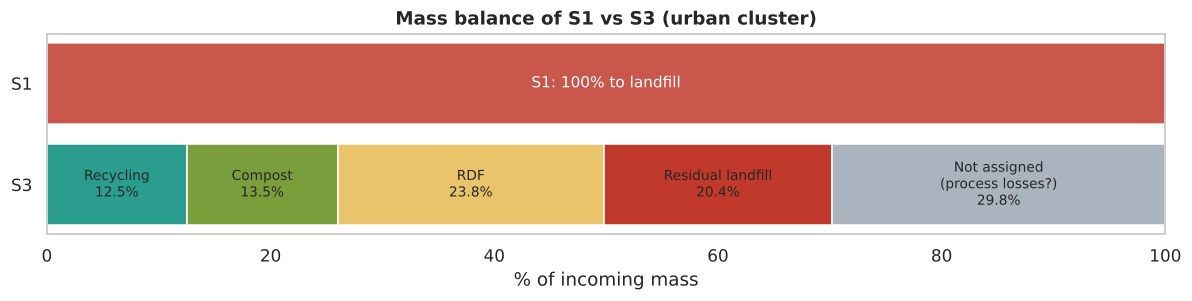

S3 outlets sum to 70.2%  →  29.8% of mass is not assigned to any outlet
Residual landfill: 51.82 t/d ÷ 254 t/d = 20.4%  (matches the 20.4% quoted)


In [14]:
s3 = {"Recycling": 12.5, "Compost": 13.5, "RDF": 23.8, "Residual landfill": 20.4}
unacc = 100 - sum(s3.values())
RESULTS.update(s3_unaccounted_pct=float(unacc), s3_landfill_pct=20.4, s3_landfill_tpd=51.82,
               s3_landfill_check_pct=float(100*51.82/254), landfill_reduction_pct=float(100 - 20.4))
fig, ax = plt.subplots(figsize=(11, 2.9))
left = 0
for (k, v), c in zip(list(s3.items()) + [("Not assigned\n(process losses?)", unacc)], [PAL["S3"], "#7a9e3b", PAL["other"], PAL["S1"], PAL["derived"]]):
    ax.barh(0, v, left=left, color=c, edgecolor="white"); ax.text(left + v/2, 0, f"{k}\n{v:.1f}%", ha="center", va="center", fontsize=9); left += v
ax.barh(1, 100, color=PAL["S1"], alpha=.85); ax.text(50, 1, "S1: 100% to landfill", ha="center", va="center", color="white", fontsize=10)
ax.set_yticks([0, 1]); ax.set_yticklabels(["S3", "S1"]); ax.set_xlim(0, 100); ax.set_xlabel("% of incoming mass")
ax.set_title("Mass balance of S1 vs S3 (urban cluster)"); ax.grid(False)
savefig("fig07_s3_mass_balance")
print(f"S3 outlets sum to {sum(s3.values()):.1f}%  →  {unacc:.1f}% of mass is not assigned to any outlet")
print(f"Residual landfill: 51.82 t/d ÷ 254 t/d = {100*51.82/254:.1f}%  (matches the 20.4% quoted)")

**Insight 4.** S3 sends 20.4 % of the waste to landfill (51.82 of 254 t/d) — an **~80 % cut in landfilled mass**. The stated outlets sum to only ~70 %, so **~30 % of input mass is unassigned**; it is plausibly moisture/biodegradation loss in composting and RDF drying, but it should be confirmed in the group's design calculations because the "79.6 % recovery" in the province sheet counts this mass as "utilised".

### 4.4 What do the budgets actually say? (cost per tonne cross-check)

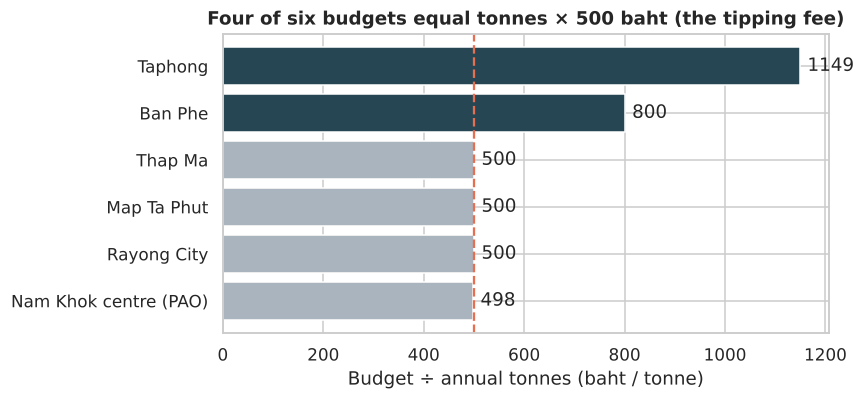

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.8))
o = fac_cost.sort_values("baht_per_tonne")
ax.barh(o.site_short, o.baht_per_tonne, color=[PAL["derived"] if abs(v - 500) < 3 else PAL["reported"] for v in o.baht_per_tonne])
ax.axvline(500, ls="--", c=PAL["accent"]); ax.set_xlabel("Budget ÷ annual tonnes (baht / tonne)")
for i, v in enumerate(o.baht_per_tonne): ax.text(v + 15, i, f"{v:.0f}", va="center")
ax.set_title("Four of six budgets equal tonnes × 500 baht (the tipping fee)")
savefig("fig08_budget_per_tonne")
RESULTS["n_budget_at_500"] = int((abs(fac_cost.baht_per_tonne - 500) < 3).sum())

**Insight 5.** Four of six listed budgets are almost exactly *tonnes × 500 baht/t* — the published tipping fee — so they are derived, not independent contract costs. Only Taphong (≈1,150 baht/t) and Ban Phe (≈800 baht/t) look like true collection/contract prices. Budgets should therefore not be used as evidence of real collection cost in the economic comparison.

---
## Part 5 — Data Visualization
Figures 01–08 above were produced with one design rule set: *one message per figure*, an action title that states the finding, colour = meaning (teal = recovery/S3, red = landfill/S1, grey = derived data), and a hatch/label for non-observed values. The panel below condenses the four findings that matter most for the design, and all figures are saved in `figures/`.

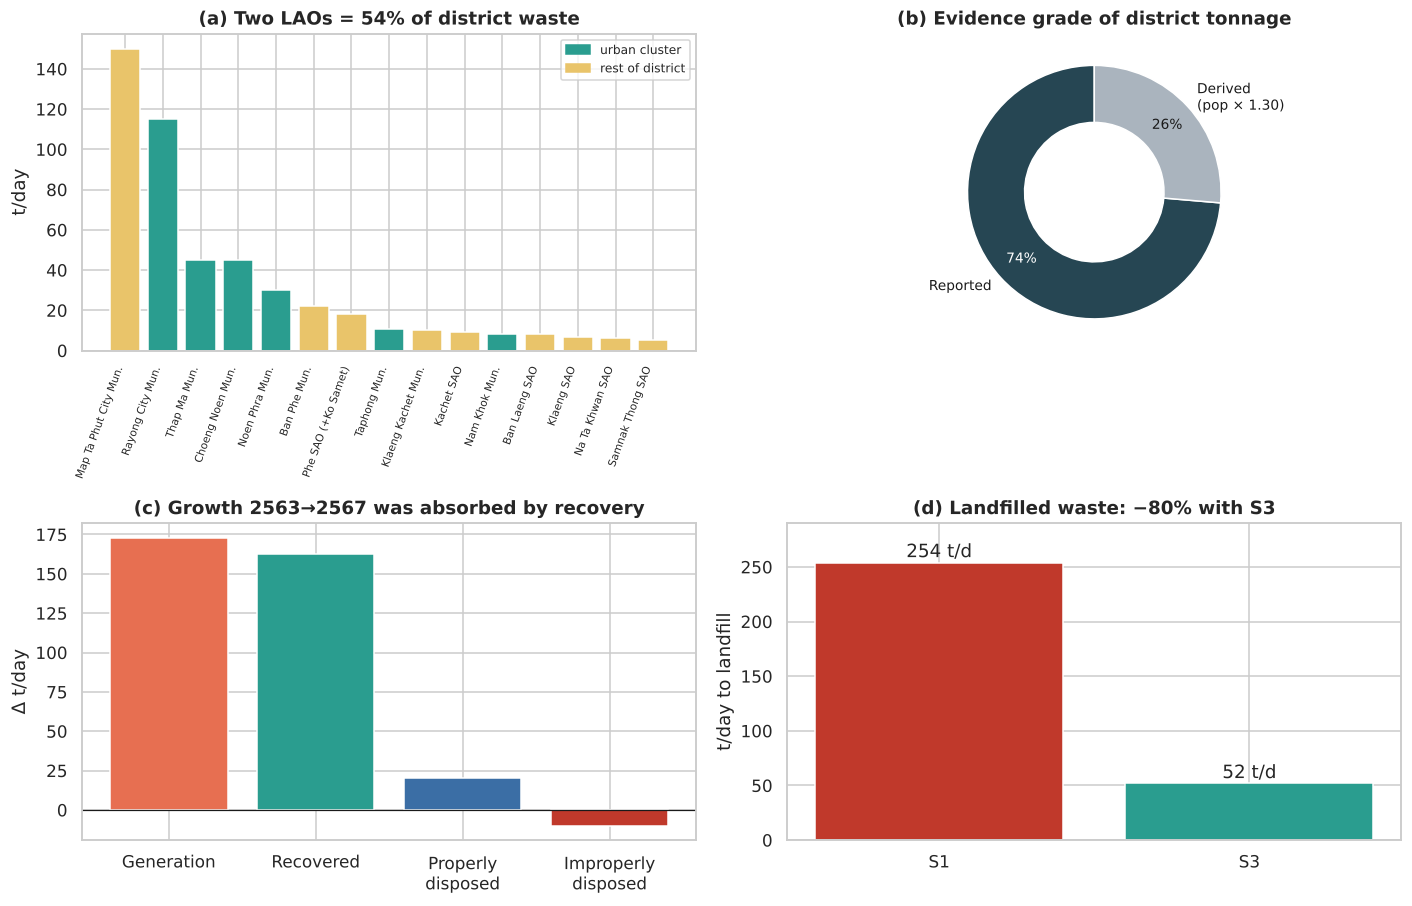

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8.4))
# (a) concentration
o = lao.sort_values("tpd", ascending=False)
ax[0, 0].bar(range(len(o)), o.tpd, color=[PAL["cluster"] if c else PAL["other"] for c in o.in_urban_cluster])
ax[0, 0].set_xticks(range(len(o))); ax[0, 0].set_xticklabels(o.lao_en, rotation=70, ha="right", fontsize=7)
ax[0, 0].set_title(f"(a) Two LAOs = {RESULTS['top2_share_pct']:.0f}% of district waste"); ax[0, 0].set_ylabel("t/day")
ax[0, 0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PAL["cluster"]), plt.Rectangle((0, 0), 1, 1, color=PAL["other"])],
                labels=["urban cluster", "rest of district"], fontsize=8)
# (b) evidence grade
ax[0, 1].pie([RESULTS["district_reported_share_pct"], RESULTS["district_derived_share_pct"]], colors=[PAL["reported"], PAL["derived"]],
             labels=["Reported", "Derived\n(pop × 1.30)"], autopct="%.0f%%", startangle=90, pctdistance=.78,
             wedgeprops=dict(width=.45), textprops=dict(fontsize=9, color="k"))
for t_ in ax[0, 1].texts[2:3]: t_.set_color("white")
ax[0, 1].set_title("(b) Evidence grade of district tonnage")
# (c) province growth attribution
ax[1, 0].bar(["Generation", "Recovered", "Properly\ndisposed", "Improperly\ndisposed"], delta.values, color=cols)
ax[1, 0].axhline(0, c="k", lw=.8); ax[1, 0].set_title("(c) Growth 2563→2567 was absorbed by recovery"); ax[1, 0].set_ylabel("Δ t/day")
# (d) landfill mass
ax[1, 1].bar(["S1", "S3"], [254, 51.82], color=[PAL["S1"], PAL["S3"]])
for i, v in enumerate([254, 51.82]): ax[1, 1].text(i, v + 5, f"{v:.0f} t/d", ha="center")
ax[1, 1].set_title("(d) Landfilled waste: −80% with S3"); ax[1, 1].set_ylabel("t/day to landfill"); ax[1, 1].set_ylim(0, 290)
savefig("fig09_key_insights_panel")

---
## Part 6 — Basic Machine Learning & Simulation (optional)
With n = 15 LAOs and n = 5 observed years, and with the circularity found in Part 3, **supervised prediction of waste from population is not defensible**. Instead we use methods that are *valid* for this data: (6.1) unsupervised segmentation of LAOs for logistics planning, (6.2) a transparent regression trend with leave-one-out validation and scenario bands for the 20-year design horizon, (6.3) Monte-Carlo propagation of composition uncertainty to design flows, and (6.4) a robustness analysis of S1 vs S3.
### 6.1 K-means segmentation of the 15 LAOs (collection / transfer planning)

Silhouette by k: {2: 0.637, 3: 0.695, 4: 0.662, 5: 0.579} → k = 3


,n_lao,min_tpd,max_tpd,total_tpd,members,share_pct
tier,,,,,,
Tier A (large),2,115.0,150.0,265.0,"Rayong City Mun., Map Ta Phut City Mun.",54.1
Tier B (medium),5,18.0,45.0,160.0,"Thap Ma Mun., Choeng Noen Mun., Noen Phra Mun....",32.7
Tier C (small),8,5.5,10.9,65.0,"Taphong Mun., Nam Khok Mun., Klaeng Kachet Mun...",13.3


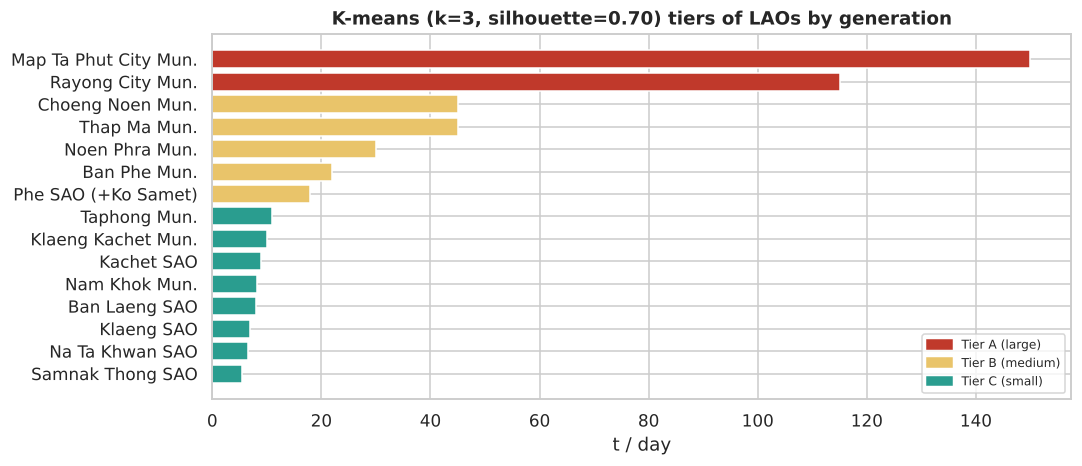

In [17]:
X = np.log10(lao[["tpd"]].values)
sil = {k: silhouette_score(X, KMeans(k, n_init=20, random_state=42).fit_predict(X)) for k in range(2, 6)}
k_best = max(sil, key=sil.get)
km = KMeans(k_best, n_init=20, random_state=42).fit(X)
lao["tier_raw"] = km.labels_
order = lao.groupby("tier_raw").tpd.mean().sort_values(ascending=False).index.tolist()
names = ["Tier A (large)", "Tier B (medium)", "Tier C (small)", "Tier D (very small)", "Tier E"][:k_best]
lao["tier"] = lao.tier_raw.map({t: n for t, n in zip(order, names)})
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()}, "→ k =", k_best)
tier_tbl = lao.groupby("tier").agg(n_lao=("lao_en", "size"), min_tpd=("tpd", "min"), max_tpd=("tpd", "max"), total_tpd=("tpd", "sum"),
                                   members=("lao_en", lambda s: ", ".join(s))).sort_values("total_tpd", ascending=False)
tier_tbl["share_pct"] = 100 * tier_tbl.total_tpd / lao.tpd.sum()
tier_tbl.to_csv(PROC/"lao_tiers.csv"); display(tier_tbl.round(1))
RESULTS["k_best"] = int(k_best); RESULTS["silhouette"] = float(sil[k_best])
RESULTS["tiers"] = {t: dict(n=int(r.n_lao), min_tpd=float(r.min_tpd), max_tpd=float(r.max_tpd), share_pct=float(r.share_pct)) for t, r in tier_tbl.iterrows()}
fig, ax = plt.subplots(figsize=(10, 4.4)); o = lao.sort_values("tpd")
tcol = dict(zip(names, [PAL["S1"], PAL["other"], PAL["S3"], PAL["blue"], PAL["derived"]]))
ax.barh(o.lao_en, o.tpd, color=o.tier.map(tcol)); ax.set_xlabel("t / day")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=tcol[n]) for n in names], labels=names, loc="lower right", fontsize=8)
ax.set_title(f"K-means (k={k_best}, silhouette={sil[k_best]:.2f}) tiers of LAOs by generation")
savefig("fig10_lao_tiers_kmeans")

**Use in design:** Tier A LAOs can ship full truck-loads directly to the MRF/landfill; the many small LAOs in the lowest tier are candidates for shared transfer points to avoid half-empty long-haul trips.

### 6.2 Trend regression + scenario bands for the 20-year design horizon

Linear trend 2563–2567: +43.6 t/d per year, R²=1.000, leave-one-out RMSE=2.2 t/d
Out-of-sample check: trend predicts 1643 t/d for 2568 vs provincial plan 1614 (+1.8%)


,"Low (plan growth, compounding)",Base (linear trend),"High (historical CAGR, compounding)"
t/day (calendar-day),,,
0,254.0,254.0,254.0
10,280.3,323.2,338.2
20,309.4,392.5,450.4


,"Low (plan growth, compounding)",Base (linear trend),"High (historical CAGR, compounding)"
t/working day (MRF),,,
0,309.0,309.0,309.0
10,341.0,393.2,411.5
20,376.4,477.5,548.0


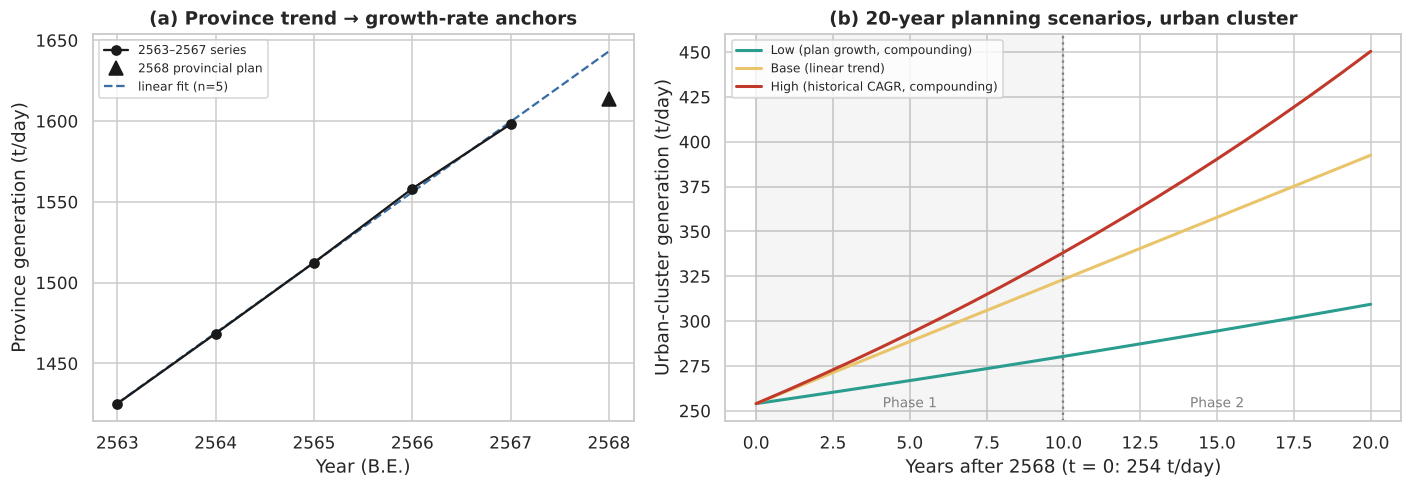

In [18]:
obs = prov[prov.year_be <= 2567]
x, y = obs.year_be.values.astype(float), obs.gen_tpd.values
lr = stats.linregress(x, y)
loo = [y[i] - np.polyval(np.polyfit(np.delete(x, i), np.delete(y, i), 1), x[i]) for i in range(len(x))]
rmse_loo = float(np.sqrt(np.mean(np.square(loo))))
pred_2568 = lr.intercept + lr.slope * 2568
plan_2568 = float(prov.loc[prov.year_be == 2568, "gen_tpd"].iloc[0])
RESULTS.update(slope_tpd_per_year=float(lr.slope), r2=float(lr.rvalue**2), rmse_loo=rmse_loo, pred_2568=float(pred_2568), plan_2568=plan_2568,
               pred_vs_plan_pct=float(100*(pred_2568 - plan_2568)/plan_2568))
print(f"Linear trend 2563–2567: +{lr.slope:.1f} t/d per year, R²={lr.rvalue**2:.3f}, leave-one-out RMSE={rmse_loo:.1f} t/d")
print(f"Out-of-sample check: trend predicts {pred_2568:.0f} t/d for 2568 vs provincial plan {plan_2568:.0f} ({RESULTS['pred_vs_plan_pct']:+.1f}%)")

g_low = plan_2568 / prov.loc[prov.year_be == 2567, "gen_tpd"].iloc[0] - 1       # plan growth 2567→2568
g_lin = lr.slope / prov.loc[prov.year_be == 2567, "gen_tpd"].iloc[0]            # linear trend (additive)
g_high = cagr                                                                    # historical CAGR (compounding)
t = np.arange(0, 21); base = 254.0                                              # t=0 is 2568 (254 t/d baseline)
scen = pd.DataFrame({"year_from_2568": t,
                     "Low (plan growth, compounding)": base * (1 + g_low) ** t,
                     "Base (linear trend)": base * (1 + g_lin * t),
                     "High (historical CAGR, compounding)": base * (1 + g_high) ** t})
scen.to_csv(PROC/"cluster_scenarios_20yr.csv", index=False)
tab = scen[scen.year_from_2568.isin([0, 10, 20])].set_index("year_from_2568").round(1)
tab_mrf = (tab * 365 / 300).round(1)
display(tab.rename_axis("t/day (calendar-day)")); display(tab_mrf.rename_axis("t/working day (MRF)"))
RESULTS.update(g_low_pct=float(100*g_low), g_lin_pct=float(100*g_lin), g_high_pct=float(100*g_high),
               yr10=tab.loc[10].to_dict(), yr20=tab.loc[20].to_dict(), yr10_mrf=tab_mrf.loc[10].to_dict(), yr20_mrf=tab_mrf.loc[20].to_dict())
cum_t = {c: float((scen[c].iloc[1:21] * 365).sum()) for c in scen.columns[1:]}
RESULTS["cum_waste_20yr_Mt"] = {k: v/1e6 for k, v in cum_t.items()}
RESULTS["cum_landfill_S1_Mt"] = {k: v/1e6 for k, v in cum_t.items()}
RESULTS["cum_landfill_S3_Mt"] = {k: v*0.204/1e6 for k, v in cum_t.items()}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
yrs = np.arange(2563, 2569)
ax[0].plot(obs.year_be, obs.gen_tpd, "ko-", label="2563–2567 series", zorder=5)
ax[0].plot([2568], [plan_2568], "k^", ms=9, label="2568 provincial plan")
ax[0].plot(yrs, lr.intercept + lr.slope * yrs, "--", c=PAL["blue"], label="linear fit (n=5)")
ax[0].set_xlabel("Year (B.E.)"); ax[0].set_ylabel("Province generation (t/day)"); ax[0].legend(fontsize=8)
ax[0].set_title("(a) Province trend → growth-rate anchors")
for c, col in zip(scen.columns[1:], [PAL["S3"], PAL["other"], PAL["S1"]]):
    ax[1].plot(scen.year_from_2568, scen[c], c=col, lw=2, label=c)
ax[1].axvspan(0, 10, color="#000", alpha=.04); ax[1].axvline(10, c="grey", ls=":")
ax[1].text(5, 252, "Phase 1", ha="center", fontsize=9, color="grey"); ax[1].text(15, 252, "Phase 2", ha="center", fontsize=9, color="grey")
ax[1].set_xlabel("Years after 2568 (t = 0: 254 t/day)"); ax[1].set_ylabel("Urban-cluster generation (t/day)"); ax[1].legend(fontsize=8, loc="upper left")
ax[1].set_title("(b) 20-year planning scenarios, urban cluster")
savefig("fig11_forecast_scenarios")

**Reading the regression honestly.** The trend fits the 5 points very closely (R² ≈ 1, tiny LOO error) — but 2566–2568 are consistent with population × 1.30, so this tight fit is a property of how the series was built, *not* proof of predictability. We therefore do **not** use a confidence interval from the regression; instead we bracket the future with three scenarios whose growth rates come directly from the data (plan growth, linear trend, historical CAGR).

### 6.3 Monte-Carlo: how uncertain is the composition-driven design flow?
PDF reports observed ranges for Rayong: food 46.21–55.33 %, plastic 20.45–32.21 %. We sample both (triangular, mode = design value) and rescale the other six fractions proportionally so shares sum to 100 %. MRF feed is fixed at 309.03 t/working-day, so composition only moves flow *between* downstream lines.

,P5,P50,P95,design (PDF),P95 / design
Food & easily degradable organics,145.61,153.17,165.34,148.34,1.11
Plastic & foam,67.64,78.15,92.78,74.17,1.25
Paper & cardboard,21.08,27.32,32.51,30.90,1.05
"Wood, branches & leaves",8.43,10.93,13.00,12.36,1.05
"Textile, rubber & leather",8.43,10.93,13.00,12.36,1.05
Glass & broken glass,8.43,10.93,13.00,12.36,1.05
Metal & aluminium,4.22,5.46,6.50,6.18,1.05
Other / inert (stone soil sand ceramic),8.43,10.93,13.00,12.36,1.05


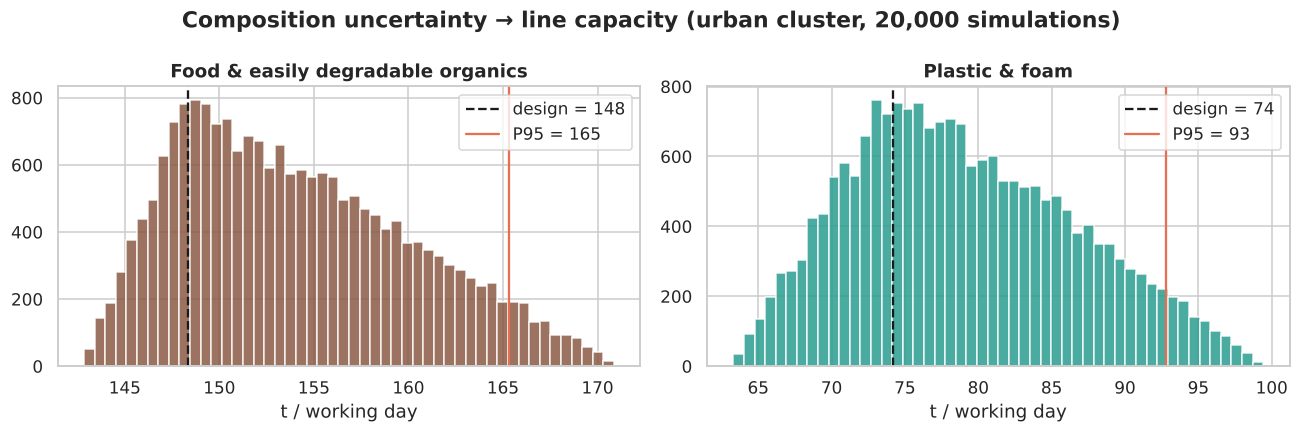

In [19]:
rng = np.random.default_rng(42); N = 20000
share = comp.set_index("category")["share_pct"]
fcat, pcat = share.index[0], share.index[1]
food = rng.triangular(46.21, 48.0, 55.33, N); plas = rng.triangular(20.45, 24.0, 32.21, N)
rest = share.drop([fcat, pcat]); scale = (100 - food - plas) / rest.sum()
sim = pd.DataFrame({fcat: food, pcat: plas}); 
for c in rest.index: sim[c] = rest[c] * scale
assert np.allclose(sim.sum(axis=1), 100)
MRF = 309.03
flow = sim / 100 * MRF
summary = flow.quantile([.05, .5, .95]).T; summary.columns = ["P5", "P50", "P95"]
summary["design (PDF)"] = comp.set_index("category")["cluster_mrf_tpd_300"]
summary["P95 / design"] = summary["P95"] / summary["design (PDF)"]
summary.round(2).to_csv(PROC/"montecarlo_composition_flows.csv"); display(summary.round(2))
RESULTS["mc_food_p95"] = float(summary.loc[fcat, "P95"]); RESULTS["mc_food_design"] = float(summary.loc[fcat, "design (PDF)"])
RESULTS["mc_food_ratio"] = float(summary.loc[fcat, "P95 / design"]); RESULTS["mc_plastic_p95"] = float(summary.loc[pcat, "P95"])
RESULTS["mc_plastic_design"] = float(summary.loc[pcat, "design (PDF)"]); RESULTS["mc_plastic_ratio"] = float(summary.loc[pcat, "P95 / design"])
RESULTS["mc_plastic_p5"] = float(summary.loc[pcat, "P5"]); RESULTS["mc_food_p5"] = float(summary.loc[fcat, "P5"])
RESULTS["mc_prob_food_above_design_pct"] = float(100 * (flow[fcat] > summary.loc[fcat, "design (PDF)"]).mean())
RESULTS["mc_prob_plastic_above_design_pct"] = float(100 * (flow[pcat] > summary.loc[pcat, "design (PDF)"]).mean())
RESULTS["mc_food_p50"] = float(summary.loc[fcat, "P50"]); RESULTS["mc_plastic_p50"] = float(summary.loc[pcat, "P50"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, cat, col in zip(ax, [fcat, pcat], [palette[0], palette[1]]):
    a_.hist(flow[cat], bins=50, color=col, alpha=.85)
    a_.axvline(summary.loc[cat, "design (PDF)"], c="k", ls="--", label=f"design = {summary.loc[cat, 'design (PDF)']:.0f}")
    a_.axvline(summary.loc[cat, "P95"], c=PAL["accent"], label=f"P95 = {summary.loc[cat, 'P95']:.0f}")
    a_.set_xlabel("t / working day"); a_.set_title(cat); a_.legend()
fig.suptitle("Composition uncertainty → line capacity (urban cluster, 20,000 simulations)", fontweight="bold")
savefig("fig12_montecarlo_composition")

**Insight 6.** The design values sit in the *lower part* of the observed ranges reported in the PDF (and our triangular sampling is anchored at those design values, so this is a stated assumption). Under it, the simulated food flow exceeds the design value in ~80 % of runs and the plastic flow in ~70 %; the P95/design ratio in the table is the safety factor the compost and plastic/RDF lines would need. This is a design-relevant result that the point estimate in the PDF hides.

### 6.4 Is S3 really better than S1? Economic robustness
Cost figures are taken from the group's design rows (20-year undiscounted CAPEX ÷ 20 + OPEX − revenues). First we reproduce the reported unit costs, then stress them.

In [20]:
S1 = alt[(alt.alternative.str.startswith("S1")) & (alt.scope.str.startswith("Urban"))].iloc[0]
S3 = alt[(alt.alternative.str.startswith("S3")) & (alt.scope.str.startswith("Urban"))].iloc[0]
TPY = 254 * 365; FEE = TPY * 500 / 1e6                                      # tipping fee 500 baht/t → 46.355 M baht/y
def net_cost(capex, opex, prod, fee=FEE, yrs=20): return (capex/yrs + opex - prod - fee) * 1e6 / TPY   # baht/t, + = cost
n1, n3 = net_cost(S1.capex_total_mbaht, S1.opex_mbaht_per_yr, 0), net_cost(S3.capex_total_mbaht, S3.opex_mbaht_per_yr, S3.product_revenue_mbaht_per_yr)
print(f"Tipping-fee revenue check: {FEE:.3f} M baht/y (source: 46.36)")
print(f"S1 net cost  : {n1:+.2f} baht/t   (reported {S1.reported_net_baht_per_t:+.2f})")
print(f"S3 net cost  : {n3:+.2f} baht/t   (reported {S3.reported_net_baht_per_t:+.2f})")
adv = n1 - n3; print(f"S3 advantage : {adv:.0f} baht/t  = {adv*TPY/1e6:.1f} M baht/yr")
ann1, ann3 = S1.capex_total_mbaht/20 + S1.opex_mbaht_per_yr, S3.capex_total_mbaht/20 + S3.opex_mbaht_per_yr
R_star = ann3 - ann1
RESULTS.update(n1=float(n1), n3=float(n3), advantage_baht_t=float(adv), advantage_mbaht_yr=float(adv*TPY/1e6), annual_cost_S1=float(ann1), annual_cost_S3=float(ann3),
               breakeven_product_rev_mbaht=float(R_star), breakeven_share_pct=float(100*R_star/S3.product_revenue_mbaht_per_yr),
               land_S1=float(S1.land_rai), land_S3=float(S3.land_rai), land_reduction_pct=float(100*(1 - S3.land_rai/S1.land_rai)),
               capex_S1=float(S1.capex_total_mbaht), capex_S3=float(S3.capex_total_mbaht), opex_S1=float(S1.opex_mbaht_per_yr), opex_S3=float(S3.opex_mbaht_per_yr),
               prod_rev_S3=float(S3.product_revenue_mbaht_per_yr))
print(f"Annualised cost (CAPEX/20 + OPEX): S1 = {ann1:.2f}, S3 = {ann3:.2f} M baht/y  → the choice is decided by S3's product revenue ({S3.product_revenue_mbaht_per_yr} M baht/y)")
RESULTS["breakeven_share_at_overrun"] = {f"+{int(o*100)}%": float(100*(ann3*(1+o) - ann1)/S3.product_revenue_mbaht_per_yr) for o in (0.3, 0.5)}
print("Break-even product revenue (% of assumed) if S3 CAPEX+OPEX over-run by 30% / 50%:", {k: round(v, 1) for k, v in RESULTS["breakeven_share_at_overrun"].items()})
print(f"Break-even product revenue for S3 = {R_star:.2f} M baht/y = {RESULTS['breakeven_share_pct']:.2f}% of the assumed value")

Tipping-fee revenue check: 46.355 M baht/y (source: 46.36)
S1 net cost  : +297.76 baht/t   (reported +297.76)
S3 net cost  : -586.40 baht/t   (reported -586.40)
S3 advantage : 884 baht/t  = 82.0 M baht/yr
Annualised cost (CAPEX/20 + OPEX): S1 = 73.96, S3 = 74.01 M baht/y  → the choice is decided by S3's product revenue (82.02 M baht/y)
Break-even product revenue (% of assumed) if S3 CAPEX+OPEX over-run by 30% / 50%: {'+30%': 27.1, '+50%': 45.2}
Break-even product revenue for S3 = 0.05 M baht/y = 0.06% of the assumed value


Monte-Carlo: P(S3 cheaper than S1) = 100.0%  |  S3 advantage P5/P50/P95 = 393 / 756 / 1023 baht/t


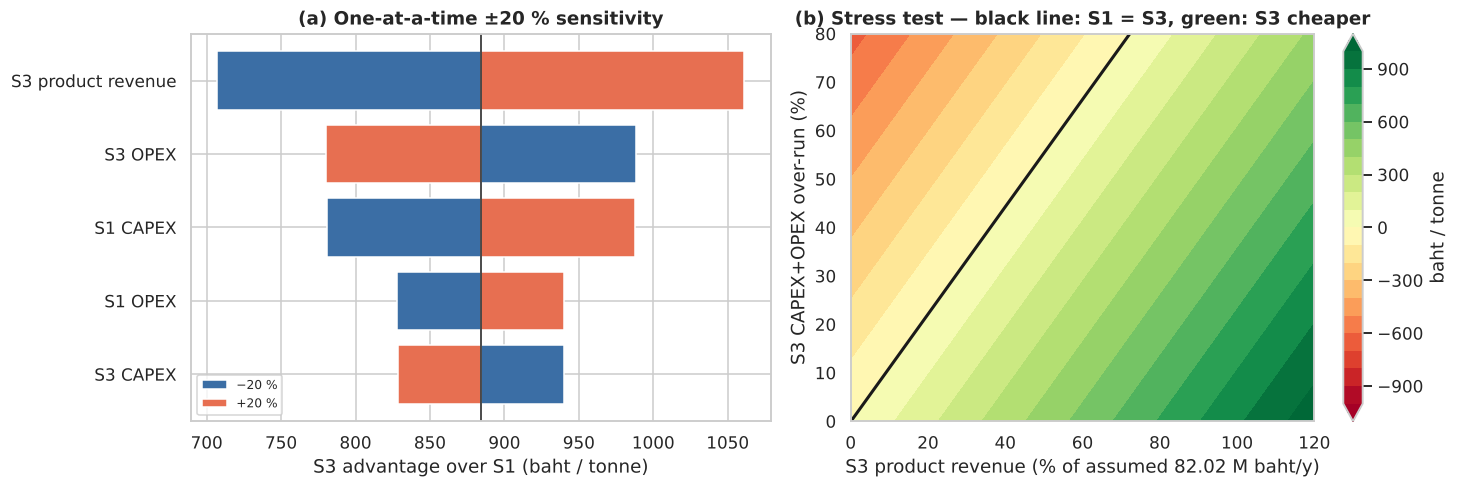

In [21]:
# One-at-a-time ±20 % tornado on the S3 advantage (S1 net − S3 net, baht/t)
base_p = dict(c1=S1.capex_total_mbaht, o1=S1.opex_mbaht_per_yr, c3=S3.capex_total_mbaht, o3=S3.opex_mbaht_per_yr, r3=S3.product_revenue_mbaht_per_yr)
def adv_fn(p): return net_cost(p["c1"], p["o1"], 0) - net_cost(p["c3"], p["o3"], p["r3"])
lab = {"c1": "S1 CAPEX", "o1": "S1 OPEX", "c3": "S3 CAPEX", "o3": "S3 OPEX", "r3": "S3 product revenue"}
rows = []
for k in base_p:
    lo, hi = [adv_fn({**base_p, k: base_p[k] * m}) for m in (0.8, 1.2)]
    rows.append((lab[k], lo, hi))
tor = pd.DataFrame(rows, columns=["parameter", "at -20%", "at +20%"]); tor["swing"] = (tor["at +20%"] - tor["at -20%"]).abs()
tor = tor.sort_values("swing"); tor.to_csv(PROC/"tornado_s3_advantage.csv", index=False)
RESULTS["tornado_min_advantage_baht_t"] = float(min(tor["at -20%"].min(), tor["at +20%"].min()))

# Monte-Carlo with ASSUMED ranges (illustrative; not from data) + stress grid
rng = np.random.default_rng(7); N = 20000
mc = dict(c1=rng.triangular(.8, 1, 1.4, N), c3=rng.triangular(.8, 1, 1.4, N), o1=rng.triangular(.9, 1, 1.3, N),
          o3=rng.triangular(.9, 1, 1.3, N), r3=rng.triangular(.3, 1, 1.2, N))
adv_mc = adv_fn({k: base_p[k] * mc[k] for k in base_p})
RESULTS.update(mc_adv_p5=float(np.percentile(adv_mc, 5)), mc_adv_p50=float(np.percentile(adv_mc, 50)), mc_adv_p95=float(np.percentile(adv_mc, 95)),
               mc_prob_s3_better_pct=float(100 * (adv_mc > 0).mean()))
print(f"Monte-Carlo: P(S3 cheaper than S1) = {RESULTS['mc_prob_s3_better_pct']:.1f}%  |  S3 advantage P5/P50/P95 = {RESULTS['mc_adv_p5']:.0f} / {RESULTS['mc_adv_p50']:.0f} / {RESULTS['mc_adv_p95']:.0f} baht/t")

rv = np.linspace(0, 1.2, 25); cm = np.linspace(1.0, 1.8, 17)
grid = np.array([[adv_fn({**base_p, "c3": base_p["c3"]*c, "o3": base_p["o3"]*c, "r3": base_p["r3"]*r}) for r in rv] for c in cm])
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.6))
ax[0].barh(tor.parameter, tor["at -20%"] - RESULTS["advantage_baht_t"], left=RESULTS["advantage_baht_t"], color=PAL["blue"], label="−20 %")
ax[0].barh(tor.parameter, tor["at +20%"] - RESULTS["advantage_baht_t"], left=RESULTS["advantage_baht_t"], color=PAL["accent"], label="+20 %")
ax[0].axvline(RESULTS["advantage_baht_t"], c="k", lw=1); ax[0].set_xlabel("S3 advantage over S1 (baht / tonne)"); ax[0].legend(fontsize=8)
ax[0].set_title("(a) One-at-a-time ±20 % sensitivity")
im = ax[1].contourf(rv * 100, (cm - 1) * 100, grid, levels=np.linspace(-1000, 1000, 21), cmap="RdYlGn", extend="both")
ax[1].contour(rv * 100, (cm - 1) * 100, grid, levels=[0], colors="k", linewidths=2)
ax[1].set_xlabel("S3 product revenue (% of assumed 82.02 M baht/y)"); ax[1].set_ylabel("S3 CAPEX+OPEX over-run (%)")
ax[1].set_title("(b) Stress test — black line: S1 = S3, green: S3 cheaper"); plt.colorbar(im, ax=ax[1], label="baht / tonne")
savefig("fig13_economic_robustness")

**Insight 7.** Annualised cost of S1 and S3 is nearly identical (≈74 M baht/y each). S3 wins because it **sells products** and needs **~75 % less land** — so the decision is robust to cost over-runs but depends on a *market for compost/RDF/recyclables*. With the numbers as given, break-even product revenue is almost zero — but the stress test (panel b) shows the margin shrinks quickly if S3 costs over-run: with a +30 % over-run S3 still needs about a quarter of the assumed product revenue, and about 45 % at +50 %. Also, S1's very large CAPEX (375 rai of land) is an assumption whose build-up should be double-checked, since it is the largest single driver of the comparison.

---
## Environmental Interpretation

In [22]:
R = RESULTS
display(Markdown(f'''
**1. System design basis.** The urban cluster generates **254 t/day** (≈{R['cluster_share_of_district_pct']:.0f}% of the 490 t/day district). Because an MRF works 300 d/y, the line must be sized for **{R['mrf_cluster']:.0f} t/working-day** (+{100*(R['working_day_factor']-1):.1f}%). Growth scenarios give **{R['yr10_mrf']['Low (plan growth, compounding)']:.0f}–{R['yr10_mrf']['High (historical CAGR, compounding)']:.0f} t/working-day in year 10** (Phase 1) and **{R['yr20_mrf']['Low (plan growth, compounding)']:.0f}–{R['yr20_mrf']['High (historical CAGR, compounding)']:.0f} t/working-day in year 20** (Phase 2) — a planning range, not a forecast.

**2. Landfill burden.** S3 cuts landfilled mass from 254 to 51.82 t/d (**−{R['landfill_reduction_pct']:.0f}%**) and land take from {R['land_S1']:.0f} to {R['land_S3']:.1f} rai (**−{R['land_reduction_pct']:.0f}%**). Over 20 years the base scenario sends **{R['cum_landfill_S1_Mt']['Base (linear trend)']:.2f} Mt** to landfill under S1 but **{R['cum_landfill_S3_Mt']['Base (linear trend)']:.2f} Mt** under S3. About 66% of the waste stream (food, wood/garden, paper, textile) is degradable organic material, so diverting it from landfill targets the main source of landfill methane and leachate load.

**3. Not yet a climate claim.** Net greenhouse-gas benefit of S3 is *not* quantified here: RDF combustion releases fossil CO₂ from plastics, and composting has its own CH₄/N₂O emissions. A proper claim needs a life-cycle/IPCC first-order-decay calculation (natural extension for a carbon-footprint analysis).

**4. Resilience.** Under the stated composition ranges, design capacity needs a margin: food flow P95 = **{R['mc_food_p95']:.0f}** vs design {R['mc_food_design']:.0f} t/wd (×{R['mc_food_ratio']:.2f}); plastic P95 = **{R['mc_plastic_p95']:.0f}** vs {R['mc_plastic_design']:.0f} (×{R['mc_plastic_ratio']:.2f}).
'''))


**1. System design basis.** The urban cluster generates **254 t/day** (≈52% of the 490 t/day district). Because an MRF works 300 d/y, the line must be sized for **309 t/working-day** (+21.7%). Growth scenarios give **341–412 t/working-day in year 10** (Phase 1) and **376–548 t/working-day in year 20** (Phase 2) — a planning range, not a forecast.

**2. Landfill burden.** S3 cuts landfilled mass from 254 to 51.82 t/d (**−80%**) and land take from 375 to 92.6 rai (**−75%**). Over 20 years the base scenario sends **2.38 Mt** to landfill under S1 but **0.49 Mt** under S3. About 66% of the waste stream (food, wood/garden, paper, textile) is degradable organic material, so diverting it from landfill targets the main source of landfill methane and leachate load.

**3. Not yet a climate claim.** Net greenhouse-gas benefit of S3 is *not* quantified here: RDF combustion releases fossil CO₂ from plastics, and composting has its own CH₄/N₂O emissions. A proper claim needs a life-cycle/IPCC first-order-decay calculation (natural extension for a carbon-footprint analysis).

**4. Resilience.** Under the stated composition ranges, design capacity needs a margin: food flow P95 = **165** vs design 148 t/wd (×1.11); plastic P95 = **93** vs 74 (×1.25).


## Limitations and recommended next data collection
* **About a quarter of district tonnage (≈26%) is simply population × 1.30**, and even the 'reported' figures are ranges/rounded values (e.g. Map Ta Phut 140–150 → 150 t/d); per-capita rate and population are therefore not independent. Collect **weighbridge records per LAO per month** (Nam Khok centre / transfer stations) to obtain real variation and seasonality.
* **Monthly seasonality is absent** (calendar effect only); tourism (Ban Phe, Ko Samet) and rainy-season moisture will matter for sizing.
* Floating population and the 50,000/95,000 study-area split are round numbers/back-calculated; verify with registration/mobile-data sources.
* 2568 values are plan figures; 2563–2566 provincial values are not marked as measured; only 2567 is labelled observed.
* **S3 mass balance leaves ~30 % unassigned** and S1/S3 CAPEX build-ups were not provided; costs use the group's totals, undiscounted.
* Monte-Carlo cost ranges are **assumed** for illustration. The regression has n = 5.
* Verify the headline figures (1,598.11 t/d; 983.66 t/d) against the cited PCD-13 report before final submission.

In [23]:
with open(PROC/"results_summary.json", "w") as f: json.dump(RESULTS, f, indent=2, default=float)
print("Saved", PROC/"results_summary.json"); print("Figures:", sorted(p.name for p in FIG.glob('*.png')))

Saved ../data/processed/results_summary.json
Figures: ['fig01_data_audit_percapita_and_monthly.png', 'fig02_evidence_grade.png', 'fig03_lao_pareto.png', 'fig04_province_trend.png', 'fig05_growth_attribution_and_percapita_base.png', 'fig06_design_flows_by_fraction.png', 'fig07_s3_mass_balance.png', 'fig08_budget_per_tonne.png', 'fig09_key_insights_panel.png', 'fig10_lao_tiers_kmeans.png', 'fig11_forecast_scenarios.png', 'fig12_montecarlo_composition.png', 'fig13_economic_robustness.png']
